# **Linear-Time Detection of Repetitive Motifs in DNA**

We install biopython to be able to import and parse fasta files (the genomics data standard)




In [1]:
!sudo apt update
!sudo apt install -y libcairo2-dev libpango1.0-dev
!pip install manim
!pip install IPython==8.21.0

Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Hit:2 https://cli.github.com/packages stable InRelease
Get:3 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Get:8 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [10.8 MB]
Hit:9 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:10 http://security.ubuntu.com/ubuntu jammy-security/main amd64 Packages [4,263 kB]
Get:11 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:12 http://archive.ubuntu.com/ubuntu jammy-updates/restricted amd64 Packages [7,965 kB]
Get:13 http://security.ubuntu.com/ubuntu jammy-security/restricted amd64 Packages [7,674 kB]
Get:14 https:/

In [2]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 11.0 MB/s eta 0:00:00


In [3]:
from manim import *

/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import timeit
from datetime import datetime
import json
from Bio import SeqIO
from array import array
import os, urllib.request, gzip, shutil
from collections import deque

We set the paths for the data of the healthy and intermediate  patient

In [5]:

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

HEALTHY_FA      = "Homo_sapiens.GRCh38.dna.chromosome.4.fa"
INTERMEDIATE_FA = "T2T_CHM13v2_chromosome_4.fa"

FILES = {
    HEALTHY_FA:
        "https://ftp.ensembl.org/pub/release-110/fasta/homo_sapiens/dna/Homo_sapiens.GRCh38.dna.chromosome.4.fa.gz",
    INTERMEDIATE_FA:
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id=NC_060928.1&rettype=fasta&retmode=text",
}

for fname, url in FILES.items():
    path = os.path.join(DATA_DIR, fname)
    if os.path.exists(path):
        print("already present:", path)
        continue
    print("downloading:", fname)
    if url.endswith(".gz"):
        urllib.request.urlretrieve(url, path + ".gz")
        with gzip.open(path + ".gz", "rb") as fin, open(path, "wb") as fout:
            shutil.copyfileobj(fin, fout)
        os.remove(path + ".gz")
    else:
        urllib.request.urlretrieve(url, path)
    print("done:", path)

patient_healthy                 = os.path.join(DATA_DIR, HEALTHY_FA)
patient_huntington_intermediate = os.path.join(DATA_DIR, INTERMEDIATE_FA)

downloading: Homo_sapiens.GRCh38.dna.chromosome.4.fa
done: data/Homo_sapiens.GRCh38.dna.chromosome.4.fa
downloading: T2T_CHM13v2_chromosome_4.fa
done: data/T2T_CHM13v2_chromosome_4.fa


We extract the sequences for both healthy and intermediate  patient

In [6]:
def load_fasta(path):
    record = next(SeqIO.parse(path, "fasta"))
    print(record.description, "-", len(record.seq), "bp")
    return str(record.seq)

sequence_healthy      = load_fasta(patient_healthy)
sequence_intermediate = load_fasta(patient_huntington_intermediate)

4 dna:chromosome chromosome:GRCh38:4:1:190214555:1 REF - 190214555 bp
NC_060928.1 Homo sapiens isolate CHM13 chromosome 4, alternate assembly T2T-CHM13v2.0 - 193574945 bp


The sequence is approximately 190 million nucleotides.


Meanwhile for the unhealthy patient we input directly into the cell the data, we will later explain how the data has been sourced.

In [7]:
ILL_genome_plasmid = "CATGCATTAGTTATTAATAGTAATCAATTACGGGGTCATTAGTTCATAGCCCATATATGGAGTTCCGCGTTACATAACTTACGGTAAATGGCCCGCCTGGCTGACCGCCCAACGACCCCCGCCCATTGACGTCAATAATGACGTATGTTCCCATAGTAACGCCAATAGGGACTTTCCATTGACGTCAATGGGTGGAGTATTTACGGTAAACTGCCCACTTGGCAGTACATCAAGTGTATCATATGCCAAGTACGCCCCCTATTGACGTCAATGACGGTAAATGGCCCGCCTGGCATTATGCCCAGTACATGACCTTATGGGACTTTCCTACTTGGCAGTACATCTACGTATTAGTCATCGCTATTACCATGGTGATGCGGTTTTGGCAGTACATCAATGGGCGTGGATAGCGGTTTGACTCACGGGGATTTCCAAGTCTCCACCCCATTGACGTCAATGGGAGTTTGTTTTGGCACCAAAATCAACGGGACTTTCCAAAATGTCGTAACAACTCCGCCCCATTGACGCAAATGGGCGGTAGGCGTGTACGGTGGGAGGTCTATATAAGCAGAGCTGGTTTAGTGAACCGTCAGATCCGCTAGCGCTACCGGTCGCCACCATGGTGAGCAAGGGCGAGGAGCTGTTCACCGGGGTGGTGCCCATCCTGGTCGAGCTGGACGGCGACGTAAACGGCCACAAGTTCAGCGTGTCCGGCGAGGGCGAGGGCGATGCCACCTACGGCAAGCTGACCCTGAAGTTCATCTGCACCACCGGCAAGCTGCCCGTGCCCTGGCCCACCCTCGTGACCACCCTGACCTACGGCGTGCAGTGCTTCAGCCGCTACCCCGACCACATGAAGCAGCACGACTTCTTCAAGTCCGCCATGCCCGAAGGCTACGTCCAGGAGCGCACCATCTTCTTCAAGGACGACGGCAACTACAAGACCCGCGCCGAGGTGAAGTTCGAGGGCGACACCCTGGTGAACCGCATCGAGCTGAAGGGCATCGACTTCAAGGAGGACGGCAACATCCTGGGGCACAAGCTGGAGTACAACTACAACAGCCACAACGTCTATATCATGGCCGACAAGCAGAAGAACGGCATCAAGGTGAACTTCAAGATCCGCCACAACATCGAGGACGGCAGCGTGCAGCTCGCCGACCACTACCAGCAGAACACCCCCATCGGCGACGGCCCCGTGCTGCTGCCCGACAACCACTACCTGAGCACCCAGTCCGCCCTGAGCAAAGACCCCAACGAGAAGCGCGATCACATGGTCCTGCTGGAGTTCGTGACCGCCGCCGGGATCACTCTCGGCATGGACGAGCTGTACAAGTCCGGACTCAGATCTATGAAGGCCTTCGAGTCCCTCAAGTCCTTCCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAACAGCCGCCACCGCCGCCGCCGCCGCCGCCGCCTCCTCAGCTTCCTCAGCCGCCGAATTCTGCAGTCGACGGTACCGCGGGCCCGGGATCCACCGGATCTAGATAACTGATCATAATCAGCCATACCACATTTGTAGAGGTTTTACTTGCTTTAAAAAACCTCCCACACCTCCCCCTGAACCTGAAACATAAAATGAATGCAATTGTTGTTGTTAACTTGTTTATTGCAGCTTATAATGGTTACAAATAAAGCAATAGCATCACAAATTTCACAAATAAAGCATTTTTTTCACTGCATTCTAGTTGTGGTTTGTCCAAACTCATCAATGTATCTTAACGCGTAAATTGTAAGCGTTAATATTTTGTTAAAATTCGCGTTAAATTTTTGTTAAATCAGCTCATTTTTTAACCAATAGGCCGAAATCGGCAAAATCCCTTATAAATCAAAAGAATAGACCGAGATAGGGTTGAGTGTTGTTCCAGTTTGGAACAAGAGTCCACTATTAAAGAACGTGGACTCCAACGTCAAAGGGCGAAAAACCGTCTATCAGGGCGATGGCCCACTACGTGAACCATCACCCTAATCAAGTTTTTTGGGGTCGAGGTGCCGTAAAGCACTAAATCGGAACCCTAAAGGGAGCCCCCGATTTAGAGCTTGACGGGGAAAGCCGGCGAACGTGGCGAGAAAGGAAGGGAAGAAAGCGAAAGGAGCGGGCGCTAGGGCGCTGGCAAGTGTAGCGGTCACGCTGCGCGTAACCACCACACCCGCCGCGCTTAATGCGCCGCTACAGGGCGCGTCAGGTGGCACTTTTCGGGGAAATGTGCGCGGAACCCCTATTTGTTTATTTTTCTAAATACATTCAAATATGTATCCGCTCATGAGACAATAACCCTGATAAATGCTTCAATAATATTGAAAAAGGAAGAGTCCTGAGGCGGAAAGAACCAGCTGTGGAATGTGTGTCAGTTAGGGTGTGGAAAGTCCCCAGGCTCCCCAGCAGGCAGAAGTATGCAAAGCATGCATCTCAATTAGTCAGCAACCAGGTGTGGAAAGTCCCCAGGCTCCCCAGCAGGCAGAAGTATGCAAAGCATGCATCTCAATTAGTCAGCAACCATAGTCCCGCCCCTAACTCCGCCCATCCCGCCCCTAACTCCGCCCAGTTCCGCCCATTCTCCGCCCCATGGCTGACTAATTTTTTTTATTTATGCAGAGGCCGAGGCCGCCTCGGCCTCTGAGCTATTCCAGAAGTAGTGAGGAGGCTTTTTTGGAGGCCTAGGCTTTTGCAAAGATCGATCAAGAGACAGGATGAGGATCGTTTCGCATGATTGAACAAGATGGATTGCACGCAGGTTCTCCGGCCGCTTGGGTGGAGAGGCTATTCGGCTATGACTGGGCACAACAGACAATCGGCTGCTCTGATGCCGCCGTGTTCCGGCTGTCAGCGCAGGGGCGCCCGGTTCTTTTTGTCAAGACCGACCTGTCCGGTGCCCTGAATGAACTGCAAGACGAGGCAGCGCGGCTATCGTGGCTGGCCACGACGGGCGTTCCTTGCGCAGCTGTGCTCGACGTTGTCACTGAAGCGGGAAGGGACTGGCTGCTATTGGGCGAAGTGCCGGGGCAGGATCTCCTGTCATCTCACCTTGCTCCTGCCGAGAAAGTATCCATCATGGCTGATGCAATGCGGCGGCTGCATACGCTTGATCCGGCTACCTGCCCATTCGACCACCAAGCGAAACATCGCATCGAGCGAGCACGTACTCGGATGGAAGCCGGTCTTGTCGATCAGGATGATCTGGACGAAGAGCATCAGGGGCTCGCGCCAGCCGAACTGTTCGCCAGGCTCAAGGCGAGCATGCCCGACGGCGAGGATCTCGTCGTGACCCATGGCGATGCCTGCTTGCCGAATATCATGGTGGAAAATGGCCGCTTTTCTGGATTCATCGACTGTGGCCGGCTGGGTGTGGCGGACCGCTATCAGGACATAGCGTTGGCTACCCGTGATATTGCTGAAGAGCTTGGCGGCGAATGGGCTGACCGCTTCCTCGTGCTTTACGGTATCGCCGCTCCCGATTCGCAGCGCATCGCCTTCTATCGCCTTCTTGACGAGTTCTTCTGAGCGGGACTCTGGGGTTCGAAATGACCGACCAAGCGACGCCCAACCTGCCATCACGAGATTTCGATTCCACCGCCGCCTTCTATGAAAGGTTGGGCTTCGGAATCGTTTTCCGGGACGCCGGCTGGATGATCCTCCAGCGCGGGGATCTCATGCTGGAGTTCTTCGCCCACCCTAGGGGGAGGCTAACTGAAACACGGAAGGAGACAATACCGGAAGGAACCCGCGCTATGACGGCAATAAAAAGACAGAATAAAACGCACGGTGTTGGGTCGTTTGTTCATAAACGCGGGGTTCGGTCCCAGGGCTGGCACTCTGTCGATACCCCACCGAGACCCCATTGGGGCCAATACGCCCGCGTTTCTTCCTTTTCCCCACCCCACCCCCCAAGTTCGGGTGAAGGCCCAGGGCTCGCAGCCAACGTCGGGGCGGCAGGCCCTGCCATAGCCTCAGGTTACTCATATATACTTTAGATTGATTTAAAACTTCATTTTTAATTTAAAAGGATCTAGGTGAAGATCCTTTTTGATAATCTCATGACCAAAATCCCTTAACGTGAGTTTTCGTTCCACTGAGCGTCAGACCCCGTAGAAAAGATCAAAGGATCTTCTTGAGATCCTTTTTTTCTGCGCGTAATCTGCTGCTTGCAAACAAAAAAACCACCGCTACCAGCGGTGGTTTGTTTGCCGGATCAAGAGCTACCAACTCTTTTTCCGAAGGTAACTGGCTTCAGCAGAGCGCAGATACCAAATACTGTTCTTCTAGTGTAGCCGTAGTTAGGCCACCACTTCAAGAACTCTGTAGCACCGCCTACATACCTCGCTCTGCTAATCCTGTTACCAGTGGCTGCTGCCAGTGGCGATAAGTCGTGTCTTACCGGGTTGGACTCAAGACGATAGTTACCGGATAAGGCGCAGCGGTCGGGCTGAACGGGGGGTTCGTGCACACAGCCCAGCTTGGAGCGAACGACCTACACCGAACTGAGATACCTACAGCGTGAGCTATGAGAAAGCGCCACGCTTCCCGAAGGGAGAAAGGCGGACAGGTATCCGGTAAGCGGCAGGGTCGGAACAGGAGAGCGCACGAGGGAGCTTCCAGGGGGAAACGCCTGGTATCTTTATAGTCCTGTCGGGTTTCGCCACCTCTGACTTGAGCGTCGATTTTTGTGATGCTCGTCAGGGGGGCGGAGCCTATGGAAAAACGCCAGCAACGCGGCCTTTTTACGGTTCCTGGCCTTTTGCTGGCCTTTTGCTCACATGTTCTTTCCTGCGTTATCCCCTGATTCTGTGGATAACCGTATTACCGC"

# Algo implementation



We start by implementing a brute force algorithm to verify that our KMP algo actually works, since the former it's much easier to implement

In [8]:
s= ILL_genome_plasmid[100:750]
w= "CAG"

The brute force algorithm for each letter the m(length of the word)-letters after and sees whether that matches the word, this is the easiest to implement but the worst in terms of complexity

In [9]:
def bruteforce(text, pattern):
    occurrences = []

    n = len(text)
    m = len(pattern)

    for i in range(n - m + 1):
        j = 0

        while j < m and text[i + j] == pattern[j]:
            j += 1

        if j == m:
            occurrences.append(i)

    return occurrences

In [10]:
Out_test = bruteforce(s,w)
Out_test

[122, 202, 235, 286, 468, 490, 602]

The KMP algorithm solves the same problem but does so in a much more efficient manner. It has two parts the KMP search and the KMP error function. We start to implement the KMP error function, this function will preprocess the word and output an array useful to the search algorithm

In [11]:
def error_fun(word):
  m = len(word)
  # preallocate the failure array of length m
  F = [0]*m
  i = 1
  j = 0
  while i < m:
    if word[i]== word[j]:
      F[i] = j + 1
      i += 1
      j += 1
    elif j > 0:
      j = F[j - 1 ]
    else:
      F[i] = 0
      i += 1

  return F

Now we implement the core of the algorithm the search function:


In [12]:
def KMP(string,word):
  # this is a list of index the beginning of the position of the matched word
  answerlist = []
  # the failure array is precomputed once,
  # so it is not rebuilt during the scan
  F = error_fun(word)
  i = 0
  j = 0
  n = len(string)
  m = len(word)
  while i < n :
    #if the letters match
    if string[i] == word[j]:

      #if we matched all letters
      if j == m - 1:
        answerlist.append(i - m + 1)
        j = F[j]
        i += 1

      #if we haven't yet matched all
      else:
        i += 1
        j += 1

    #if they dont match
    else:
      # if we already matched a letter
      if j > 0:
        # word skips to the F[j-1]th letter
        j = F[j - 1]


      #if we haven't yet matched anything
      else:
        # we just move to the next string's letter
        i += 1

  return answerlist

We try to run our program on the same problem given to the KMP brute force algorithm:

In [13]:
Out_test1 =KMP(s,w)
Out_test1

[122, 202, 235, 286, 468, 490, 602]

This confirms that the two algorithms (the brute force matching and the KMP) are equivalent with respect to the results:

In [14]:
Out_test == Out_test1

True

Our implementation of the KMP algorithm works

# Toy example

In [15]:
pattern = "CACAC"
DNA_string = "CAGCACACAC"

We modify the previous code this is a code that yields a generator (similar to iterables) at each steps simply tells the animator what i and j mean.

In [16]:
def KMP_modif(string,word):
  answerlist = []
  F = error_fun(word)
  i = 0
  j = 0
  yield(i,j,answerlist, False)
  n = len(string)
  m = len(word)
  while i < n :
    Flag = False
    if string[i] == word[j]:
      if j == m - 1:
        answerlist.append(i - m + 1)
        Flag= True
        j = F[j]
        i += 1
      else:
        i += 1
        j += 1
    else:
      if j > 0:
        j = F[j - 1]
      else:
        i += 1
    yield(i,j,answerlist, Flag)

We animate step by step the KMP algorithm working:

In [17]:
%%manim -qm -v WARNING KMPscene


# adjust the frame size depending on how long the DNA string is
TILE_SIZE = 1.5
config.frame_height = 8
config.frame_width = max(16, TILE_SIZE* len(DNA_string) + 5)

# keep the output resolution proportional to the frame dimensions
config.pixel_height = 480
config.pixel_width = int(
    config.pixel_height * config.frame_width / config.frame_height
)
config.pixel_width += config.pixel_width % 2

def tile_letter(letter: str) -> VGroup: # the input is a char and the output a VGroup
    # Create a square containing one character
    sq = Square(side_length=TILE_SIZE, color=GREEN).set_stroke(width=2)
    text = Text(letter, color=BLACK).scale(0.7).move_to(sq.get_center())
    return VGroup(sq, text)

def whole_string(stringa: str) -> VGroup:
    # apply the previous function to all the letter in string
    return VGroup(*[tile_letter(char) for char in stringa]).arrange(buff=0)


# Folder where the each screenshots and their metadata are written.
SCREENSHOT_DIR = "kmp_screenshots"


class KMPscene(Scene):
    def construct(self):
        self.camera.background_color = WHITE

        #create Vgroups
        textMO = whole_string(DNA_string)
        patternMO = whole_string(pattern)

        #position the text
        textMO.to_edge(UP, buff =1.5)
        #position the pattern
        patternMO.next_to(textMO[0], DOWN, buff=0.6, index_of_submobject_to_align=0)


        self.play(Write(textMO))
        self.play(Write(patternMO))

        # this avoid that the colour refresh creates some weird artifact
        self.add_foreground_mobjects(*[tile[1] for tile in patternMO], *[tile[1] for tile in textMO])

        lista = []

        # these alone wont refresh the picture
        i_tracker = ValueTracker(0)
        j_tracker = ValueTracker(0)

        # We keep the picture updated
        labels = always_redraw(
            lambda: VGroup(
                Text(f"i: {int(i_tracker.get_value())}", color=BLACK),
                Text(f"j: {int(j_tracker.get_value())}", color=BLACK),
                Text(f"answerlist: {lista}", font_size=24, color=BLACK),
            ).arrange(DOWN, buff=0.3).to_corner(DR, buff=0.5)
        )

        self.add(labels)
        # Prepare the folder and metadata for the screenshots

        os.makedirs(SCREENSHOT_DIR, exist_ok=True)
        self.shot_idx = 0
        self.shot_meta = []

        def save_screenshot(i, j, ans, hit):
            # Force Manim to refresh the always_redraw labels
            self.update_mobjects(0)
            try:
                self.renderer.update_frame(self)
            except Exception:
                self.camera.capture_mobjects(self.mobjects)
            image = self.camera.get_image()

            filename = f"kmp_step_{self.shot_idx:02d}.png"
            image.save(os.path.join(SCREENSHOT_DIR, filename))

            self.shot_meta.append({
                "step": self.shot_idx,
                "i": int(i),

                "j": int(j),
                "hit": bool(hit),
                "match_at": (int(i) - len(pattern)) if hit else None,
                "file": filename,
            })
            self.shot_idx += 1

        def animate_prefix_fill(stringMO: VGroup, index: int, run_green=0.7):
            # Highlight the part of the pattern that has already matched
            anims = []
            for k in range(len(stringMO)):
                sq = stringMO[k][0]
                if k < index:
                    anims.append(sq.animate.set_fill(GREEN, opacity=run_green))
                else:
                    anims.append(sq.animate.set_fill(WHITE, opacity=0.0))
            return AnimationGroup(*anims, lag_ratio=0)

        n = len(textMO)
        m = len(patternMO)

        # Run through the states produced by the modified KMP function
        for i, j, ans, hit in KMP_modif(DNA_string, pattern):
            i_tracker.set_value(i)
            j_tracker.set_value(j)
            lista = ans  # update what the label will print

            # Avoid aligning beyond the last character of the text
            align_i = min(int(i), n - 1)

            if hit:
                self.play(patternMO[-1][0].animate.set_fill(GREEN, opacity=0.6))

                matched_patterns = VGroup(*[t for sq, t in patternMO]) + VGroup(*[t for sq, t in textMO[i - len(pattern):i]])
                self.play(ApplyWave(matched_patterns), run_time=1)
                self.play(Transform(matched_patterns.copy(), target_mobject=labels[2][-2]), run_time=1)

                self.play(
                    AnimationGroup(
                        *[sq.animate.set_fill(WHITE, opacity=0) for sq, t in patternMO],
                        lag_ratio=0
                    ),
                    run_time=0.2
                )
            # avoids useless comparisons
            if int(i) >= n:
                  break
            # move the pattern so that P[j] is aligned with T[i] (the core of the anim)
            self.play(
                patternMO.animate.next_to(
                    textMO, DOWN,
                    buff=0.6,
                    submobject_to_align=patternMO[j],
                    index_of_submobject_to_align=align_i
                ),
                run_time=1,
                rate_func=smooth
            )
            # highlight the prefix that has already been matched
            self.play(animate_prefix_fill(patternMO, j))
            # take screenshoot
            save_screenshot(i, j, ans, hit)
            # show which two characters are currently being compared
            self.play(Indicate(VGroup(textMO[align_i][1], patternMO[j][1])), run_time=0.5)

        # Save the metadata for all generated screenshots
        with open(os.path.join(SCREENSHOT_DIR, "steps.json"), "w") as f:
            json.dump(self.shot_meta, f, indent=2)
        print(f"Saved {self.shot_idx} screenshots to '{SCREENSHOT_DIR}/'")


Manim Community v0.21.0

Saved 11 screenshots to 'kmp_screenshots/'


# Real world simulation

We now create a function that has as input the pattern that we want to look for and DNA string that is the corpus where we search the pattern. The output of the function will be the length of the consequent patterns, the number of occurrences of the pattern it self, and the longest consequent pattern.

In [18]:
def longest_run(ans_list, m):
    #Given the sorted match positions and pattern length m,
    #return (run_lengths, n_occurrences, longest_run).
    n_occ = len(ans_list)


    #edge case where the pattern is not found
    if n_occ == 0:
        return [], 0, 0
    runs = []
    current = 1
    # every match is a run of length >= 1
    for prev, nxt in zip(ans_list, ans_list[1:]):
      # contiguous repeat (ie difference is equal to pattern length)
        if nxt - prev == m:
            current += 1
        else:
            runs.append(current)
            current = 1
    runs.append(current)
    return runs, n_occ, max(runs)

In [19]:
def pattern_detector( dna , pattern ):
  ans_list = KMP(dna, pattern)
  return longest_run(ans_list, len(pattern))

## Ill patient's data


The full genome of ill patients is not available in public sources probably for privacy reasons, so we resorted to a plasmid (taken from this website https://www.addgene.org/browse/sequence/386372/)  that contains part of the ill gene. Since it’s not the entire fourth chromosome the number of base pairs to analyse is rather small. Even though it's not public there are some private data bank that sell the whole genome https://catalog.coriell.org/0/Sections/Search/Sample_Detail.aspx?Ref=GM04281&product=CC.

In [20]:
pattern = "CAG"
start_time = datetime.now()
out_ihut = pattern_detector(ILL_genome_plasmid, pattern)
end_time = datetime.now()
consequent_i, N_occurence_i, longest_chain_i = out_ihut
print(f"The number of bp scanned is {len(ILL_genome_plasmid)}")
print(f"The longest repeating {pattern} pattern in this genome is of length {longest_chain_i}")
print(f'The sequence was scanned in: {end_time - start_time}')
print(f'The number of CAG hits: {N_occurence_i}')
print(f"The number of {pattern} >= 2 is {len([r for r in consequent_i if r >= 2])}")

The number of bp scanned is 5019
The longest repeating CAG pattern in this genome is of length 72
The sequence was scanned in: 0:00:00.000622
The number of CAG hits: 156
The number of CAG >= 2 is 5


If a patient presented a repeating CAG pattern of length 72 in the correct allele, we could confidently say that the patient is ill.

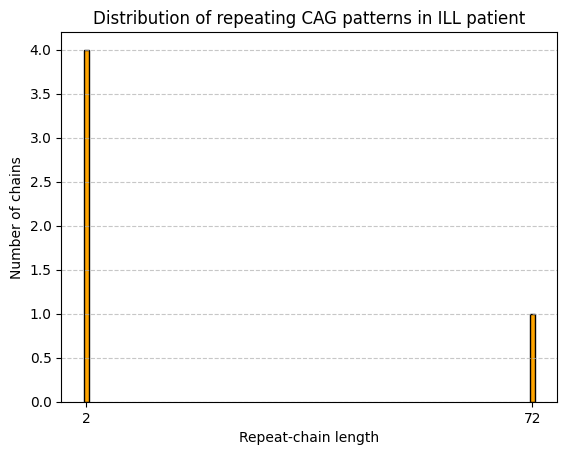

In [21]:
consequent, N_occurence, longest_chain = out_ihut
consequent2 = [r for r in consequent if r >= 2]
values, counts = np.unique(consequent2, return_counts=True)


# Plot
plt.bar(values, counts, color="orange", edgecolor="black")
plt.xlabel("Repeat-chain length")
plt.ylabel("Number of chains")
plt.title(f"Distribution of repeating {pattern} patterns in ILL patient")
plt.xticks(values)
plt.grid(axis="y", linestyle='--', alpha=0.7)
plt.show()

From this graph we see that every other repeating pattern is of length 2.

## Intermediate patient simulation

This is the intermediate-patient model: chromosome 4 from the T2T-CHM13v2.0 assembly, downloaded from [NCBI (RefSeq NC_060928.1)](https://www.ncbi.nlm.nih.gov/nuccore/NC_060928.1) in the first cell. In our scan the longest consecutive CAG tract is 28 repeats, which falls in the intermediate range: carriers are not expected to develop Huntington's disease, but the repeat is unstable and can grow longer when passed to their children, possibly crossing the disease threshold (i.e. > 36 repeats).

In [22]:
start_time = datetime.now()
out_pdhut = pattern_detector(sequence_intermediate , pattern)
end_time = datetime.now()

consequent_d, N_occurence_d, longest_chain_d = out_pdhut
print(f"The number of bp scanned is {len(sequence_intermediate)}")
print(f"The longest repeating {pattern} pattern in this genome is of length {longest_chain_d}")
print(f'The sequence was scanned in: {end_time - start_time}')
print(f'The number of {pattern}  hits: {N_occurence_d}')
print(f"The number of {pattern} >= 2 is {len([r for r in consequent_d if r >= 2])}")

The number of bp scanned is 193574945
The longest repeating CAG pattern in this genome is of length 28
The sequence was scanned in: 0:00:20.212359
The number of CAG  hits: 3537869
The number of CAG >= 2 is 64426


In just under a minute it scans approximately 190 million nucleotides, and from the output we see that the longest repeating chain is 28x3 nucleotide long.

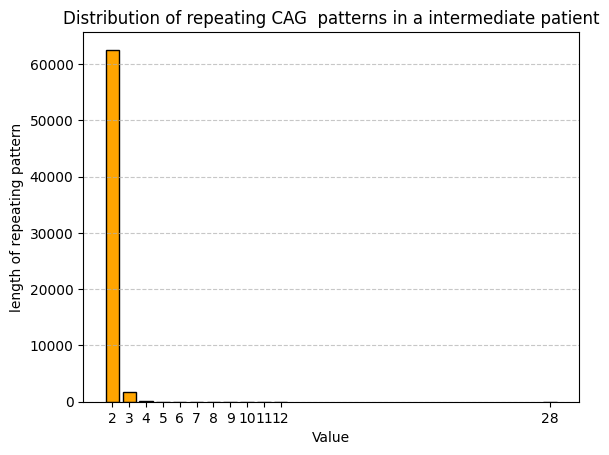

In [23]:
consequent_d2 = [r for r in consequent_d if r >= 2]
values_d, counts_d = np.unique(consequent_d2, return_counts=True)

# Plot
plt.bar(values_d, counts_d , color='orange', edgecolor='black')
plt.xlabel('Value')
plt.ylabel('length of repeating pattern')
plt.title(f'Distribution of repeating {pattern}  patterns in a intermediate patient')
plt.xticks(values_d)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

From these it is clearly shown that the most frequent repetition length is 2 but other values are present, and 28 is the longest repeating pattern. From this graph 2 and 3 dwarf every other quantity, and to solve this in the next graph we will use logarithmic scale.

We see that there are no values above 28 so we can know that the patient is not ill

## Healthy Patient simulation

This is the healthy-patient model: chromosome 4 from the GRCh38 reference assembly, downloaded from [Ensembl release 110](https://ftp.ensembl.org/pub/release-110/fasta/homo_sapiens/dna/) in the first cell. In our scan the longest consecutive CAG tract is 19 repeats, well inside the normal range , which is why this sequence plays the healthy role.

In [24]:
start_time = datetime.now()
out_phealthy = pattern_detector(sequence_healthy,pattern)
end_time = datetime.now()
consequent_h, N_occurence_h, longest_chain_h = out_phealthy
print(f"The number of bp scanned is {len(sequence_healthy)}")
print(f"The longest repeating {pattern} pattern in this genome is of length { longest_chain_h}")
print(f'The sequence was scanned in: {end_time - start_time}')
print(f'The number of {pattern}  hits: {N_occurence_h}')
print(f"The number of {pattern} >= 2 is {len([r for r in consequent_h if r >= 2])}")

The number of bp scanned is 190214555
The longest repeating CAG pattern in this genome is of length 19
The sequence was scanned in: 0:00:19.982281
The number of CAG  hits: 3456386
The number of CAG >= 2 is 63026


We graph the result of the length of the repeating patterns:

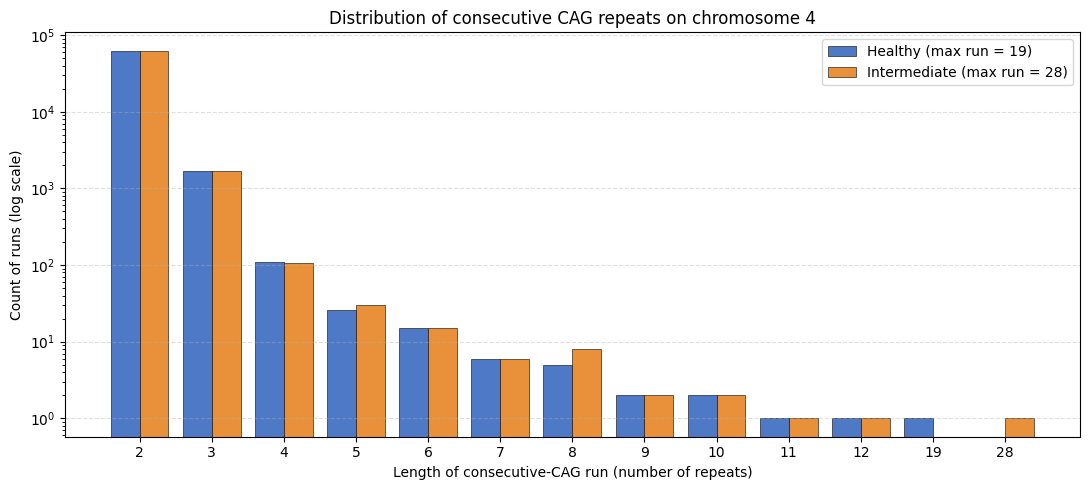

In [25]:
consequent_h2 = [r for r in consequent_h if r >= 2]
consequent_d2 = [r for r in consequent_d if r >= 2]

values_h, counts_h = np.unique(consequent_h2, return_counts=True)
values_d, counts_d = np.unique(consequent_d2, return_counts=True)


# categorical x-axis( ie the union of run lengths that appear in either genome)
all_vals = sorted(set(values_h.tolist()) | set(values_d.tolist()))
x = np.arange(len(all_vals))
width = 0.4
map_h = dict(zip(values_h.tolist(), counts_h.tolist()))
map_d = dict(zip(values_d.tolist(), counts_d.tolist()))
bars_h = [map_h.get(v, 0) for v in all_vals]
bars_d = [map_d.get(v, 0) for v in all_vals]

#plot
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - width/2, bars_h, width, color="#4E79C7", edgecolor="black", linewidth=.4,
       label=f"Healthy (max run = {int(values_h.max())})")
ax.bar(x + width/2, bars_d, width, color="#E8913A", edgecolor="black", linewidth=.4,
       label=f"Intermediate (max run = {int(values_d.max())})")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(all_vals)
ax.set_xlabel("Length of consecutive-CAG run (number of repeats)")
ax.set_ylabel("Count of runs (log scale)")
ax.set_title("Distribution of consecutive CAG repeats on chromosome 4")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.savefig("sim_cag_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Aho-Corasick

We implement the Aho-Corasick method to look for multiple patterns in the genome at once. We will see that the result are the same of the ones in the literature but with the advantage of running the algorithm only once.  

In [26]:

#we define the node properties
class TrieNode:
    def __init__(self):
        # It has 4 children pointer of course initialized as None
        self.children = [None] * 4
        # When the trie will search for this node the id of the patterns  will be released
        self.out = []
        # Pointer to a node
        self.failure_link = None

conv = {"A":0 , "C":1 , "G":2 , "T":3}
class Trie_Genome:

    def __init__(self):
        # initialize the root
        self.root = TrieNode()
        # the root has it self as failure link
        self.root.failure_link = self.root
        # this can be probably done better with a double hash map
        # each pattern is given an id
        self.patterns = {}
        self.inv_map = {}



    # Method to insert a key into the Trie
    def insert(self, key):
        # each pattern is given an id
        self.patterns[key] = len(self.patterns)
        curr = self.root
        for c in key:
            #converts the letter to a number
            index = conv[c]
            #checks if the index has a pointer to a node and if it doesn't it initializes a node
            if curr.children[index] is None:
                curr.children[index] = TrieNode()

            #moves to the children
            curr = curr.children[index]

        # the id is appended to the list
        curr.out.append(self.patterns[key])


    #Method has to be used after every pattern is inserted
    def preprocessing(self):
        # creates the inverse map id -> pattern
        self.inv_map = {v: k for k, v in self.patterns.items()}

        # This double ended queue will memorize the nodes that we need to search.
        # In reality we just need a queue not a double ended
        # queue but using a list and pop(0) is slower
        # and popleft() has been implemented only here.
        dq = deque()

        #initialized the pre-processing at the first level
        for i in range(4):
            if self.root.children[i] is not None:
              # appends all of root's children to the que
              dq.append(self.root.children[i])
              # the first level failure link are all in root
              self.root.children[i].failure_link = self.root

        # breadth-first search
        while len(dq)>0:
            # we take the first element in queue so to take the first element added to the que
            curr = dq.popleft()
            for a in range(4):
                # We focus on each child
                child = curr.children[a]
                # We check only the ones that exist
                if child is not None:

                  f = curr.failure_link
                  # It keeps jumping and checking until the son (of the node pointed by the father's failure link )
                  # is not the root (and exist) or the f is the root and has no son of with letter "conv[a]"
                  while f is not self.root and f.children[a] is None:
                      f = f.failure_link   #  multiple steps allowed

                  # we check if f has children that have a child with letter conv[a]
                  if f.children[a] is not None:
                      #we link to the longest possible suffix that is also a prefix
                      child.failure_link = f.children[a]
                  # if doesn't than the failure link is surely the root
                  else:
                      child.failure_link = self.root

                  # we just need to check the failure link and inherit all of the possible output
                  # this is possible only because we do a breath first search
                  child.out.extend(child.failure_link.out)

                  # we append the child to the END of the que
                  dq.append(child)

    def find_indices_dict(self, text):
        # init the output dictionary
        res = {p: [] for p in self.patterns}
        node = self.root

        for i, c in enumerate(text):
            #skip if the char is not in the vocabulary (C,G,T,A)
            if c not in conv:
                node = self.root
                continue
            a = conv[c]

            # we skip jump where the failure links points until the node is the root and the child is not none
            # or the node is not the root and the child is none
            while node is not self.root and node.children[a] is None:
                node = node.failure_link

            # this first of the two cases above
            if node.children[a] is not None :
              node = node.children[a]

            # this is the second of the two cases above
            else:
              node =  self.root

            # here it releases the memory of the node reached and append the result to the output dictionary
            for pid in node.out:
                pat = self.inv_map[pid]
                start = i - len(pat) + 1

                res[pat].append(start)

        return res

In [27]:
patterns = ["CAT", "AC", "TTTC", "CACA"]
dna = "CATATATATACACACATAT"

def aho_corasick(dna_in, *patterns_in):
    new_tree = Trie_Genome()

    # Insert every pattern into the same trie
    for pattern in patterns_in:
        new_tree.insert(pattern)

    # Build failure links once
    new_tree.preprocessing()

    # Search the DNA once for all patterns
    result_dic = new_tree.find_indices_dict(dna_in)

    return result_dic

out = aho_corasick(dna, *patterns)
print(out)

{'CAT': [0, 14], 'AC': [9, 11, 13], 'TTTC': [], 'CACA': [10, 12]}


We now create a function that has as input however many pattern we want to look for and a DNA string that is the corpus where we search the pattern. The output of the function will be a dictionary that will have as keys the patterns and as value a tuple that contatins the number of occurrences of the pattern it self, and the longest consequent pattern.

In [28]:
# This function takes in as many patterns as needed
def pattern_detector_aho(dna, *patterns_in):
    #searches all patterns in one Aho-Corasick scan.
    #Returns {pattern: (number of occurrences, longest consecutive run)}."""

    #single pass over the text for every pattern at once
    result_dic = aho_corasick(dna, *patterns_in)

    # post-process each pattern's match positions with the same
    # run-detection function used in the single-pattern pipeline
    for pat in result_dic:
        runs, n_occ, longest = longest_run(result_dic[pat], len(pat))
        result_dic[pat] = (n_occ, longest)

    return result_dic

We search in the data set the same patterns searched in the paper "Genomic Repeat Detection Using the Knuth-Morris-Pratt Algorithm on R High-Performance-Computing Package".



In [29]:
start_time = datetime.now()
answer_aho = pattern_detector_aho(sequence_healthy, "TTAGGG", "CAG","CCG")
end_time = datetime.now()
print('Duration: {}'.format(end_time - start_time))

Duration: 0:00:33.098079


We manage to scan the whole genome in just under a minute (including the preprocessing i.e. the making of the trie), and searching 3 patterns at the same time, this is highly efficient because it would have taken 3 scans of KMP algorithm.

In [30]:
print('Duration: {}'.format(end_time - start_time))

Duration: 0:00:33.098079


In [31]:
answer_aho

{'TTAGGG': (35503, 11), 'CAG': (3456386, 19), 'CCG': (386822, 10)}

These results match exactly the ones of previously cited paper seen in Table 4 (regarding genome 4), confirming the validity of the algorithm implemented.

# Speed benchmark

Having shown that the simulation is correct on the whole chromosome, we now judge *speed* directly. We time the three matchers, brute-force, KMP, and single-pattern Aho-Corasick (trie construction included), on real chromosome-4 slices from $10$ to $15$ million base pairs (with jump of $1$ million base pairs), repeating each measurement a few times and reporting the minimum. We deliberately use a pattern longer than the trivial `CAG` triplet.


In [32]:
pattern = "CA"*100
print(len(pattern))

200


We vary the dimension of the corpus to see how the time taken by each method evolves

In [33]:

elapsed_kmp = []
elapsed_bf = []
elapsed_aho = []

smallest_value = 10_000_000
stop_value = 16_000_000
step_size = 1_000_000


sizes = range(
    smallest_value,
    stop_value,
    step_size
)

for size in sizes:
    # Create the input once, outside the timed functions.
    text = sequence_healthy[:size]

    timer_kmp = min(
        timeit.repeat(
            lambda: KMP(text, pattern),
            repeat=8,
            number=1
        )
    )
    elapsed_kmp.append(timer_kmp)

    timer_bf = min(
        timeit.repeat(
            lambda: bruteforce(text, pattern),
            repeat=8,
            number=1
        )
    )
    elapsed_bf.append(timer_bf)

    timer_aho = min(
        timeit.repeat(
            lambda: aho_corasick(text, pattern),
            repeat=8,
            number=1
        )
    )
    elapsed_aho.append(timer_aho)

    print(
        f"n = {size:,}: "
        f"KMP = {timer_kmp:.4f} s, "
        f"Brute force = {timer_bf:.4f} s, "
        f"Aho Corasick = {timer_aho:.4f} s"
    )

n = 10,000,000: KMP = 1.0244 s, Brute force = 1.0916 s, Aho Corasick = 1.4205 s
n = 11,000,000: KMP = 1.1174 s, Brute force = 1.1962 s, Aho Corasick = 1.5530 s
n = 12,000,000: KMP = 1.2107 s, Brute force = 1.3007 s, Aho Corasick = 1.6856 s
n = 13,000,000: KMP = 1.3075 s, Brute force = 1.4016 s, Aho Corasick = 1.8206 s
n = 14,000,000: KMP = 1.4108 s, Brute force = 1.5254 s, Aho Corasick = 1.9991 s
n = 15,000,000: KMP = 1.5092 s, Brute force = 1.6207 s, Aho Corasick = 2.1334 s


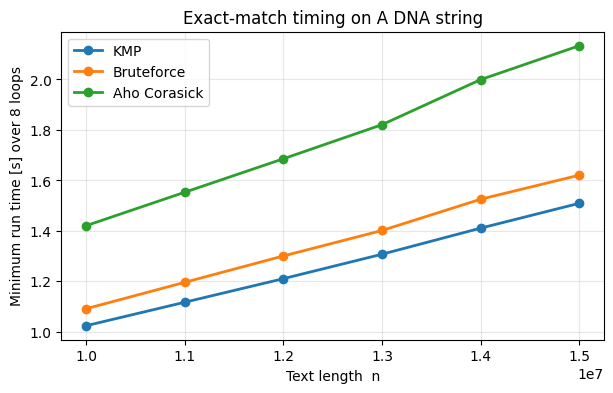

In [34]:
x1 = np.array(sizes)
ykmp = np.array(elapsed_kmp)
ybf = np.array(elapsed_bf)
yaho = np.array(elapsed_aho)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(x1, ykmp,
        marker="o", linestyle="-", linewidth=2,
        label="KMP")

ax.plot(x1, ybf,
        marker="o", linestyle="-", linewidth=2,
        label="Bruteforce")

ax.plot(x1, yaho,
        marker="o", linestyle="-", linewidth=2,
        label="Aho Corasick")

ax.set_xlabel("Text length  n")
ax.set_ylabel("Minimum run time [s] over 8 loops")
ax.set_title("Exact-match timing on A DNA string")
ax.grid(True, alpha=.3)
ax.legend()
plt.savefig("algorithm_runtime_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


For this graph we see that the KMP method always outperforms the naive method, and the Aho-Corasick.

Now for a fairer comparison we use multiple patterns:

In [35]:
patterns = [
    "CAGCAGCAG",
    "CAGCAGCAA",
    "CAGCAGCAC",
    "CAGCAGCAT",
    "CAGCAGCCG",
    "CAGCAGCTG",
    "CCGCCGCCG",
    "CTGCTGCTG",
    "GAGGAGGAG",
    "TTAGGGTTAGGG"
]
elapsed_kmp_2 = []
elapsed_aho_2 = []

smallest_value = 500_000
stop_value = 3_000_000
step_size = 500_000


sizes = range(
    smallest_value,
    stop_value,
    step_size
)

def repeated_kmp(text, patterns):
  kmp_rep_out= {}
  for pattern in patterns:
     kmp_rep_out[pattern] = KMP(text, pattern)
  return kmp_rep_out



for size in sizes:
    # Create the input once, outside the timed functions.
    text = sequence_healthy[:size]



    timer_kmp = min(
        timeit.repeat(
            lambda: repeated_kmp(text, patterns),
            repeat=8,
            number=1
        )
    )


    elapsed_kmp_2.append(timer_kmp)



    timer_aho = min(
        timeit.repeat(
            lambda: aho_corasick(text, *patterns),
            repeat=8,
            number=1
        )
    )
    elapsed_aho_2.append(timer_aho)

    print(
        f"n = {size:,}: "
        f"KMP = {timer_kmp:.4f} s, "
        f"Aho Corasick = {timer_aho:.4f} s"
    )

n = 500,000: KMP = 0.4862 s, Aho Corasick = 0.1050 s
n = 1,000,000: KMP = 1.0071 s, Aho Corasick = 0.1673 s
n = 1,500,000: KMP = 1.5352 s, Aho Corasick = 0.2514 s
n = 2,000,000: KMP = 2.0599 s, Aho Corasick = 0.3420 s
n = 2,500,000: KMP = 2.5539 s, Aho Corasick = 0.4225 s


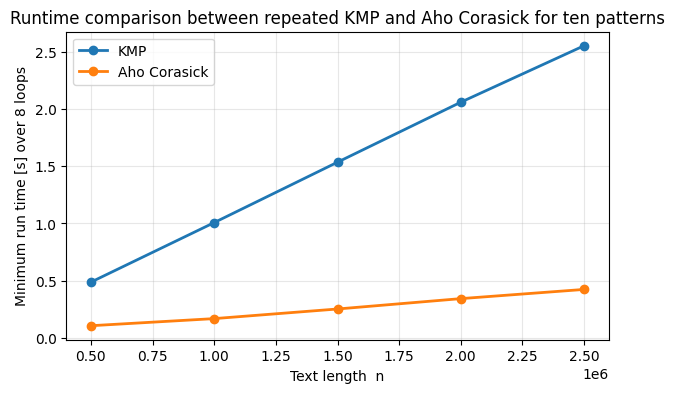

In [36]:
x1 = np.array(sizes)
ykmp = np.array(elapsed_kmp_2)
yaho = np.array(elapsed_aho_2)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(x1, ykmp,
        marker="o", linestyle="-", linewidth=2,
        label="KMP")


ax.plot(x1, yaho,
        marker="o", linestyle="-", linewidth=2,
        label="Aho Corasick")

ax.set_xlabel("Text length  n")
ax.set_ylabel("Minimum run time [s] over 8 loops")
ax.set_title("Runtime comparison between repeated KMP and Aho Corasick for ten patterns")
ax.grid(True, alpha=.3)
ax.legend()
plt.savefig("algorithm_runtime_comparison_2.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
repeated_kmp(text, patterns) == aho_corasick(text, *patterns)

True

In [38]:
import shutil

folder_name = 'kmp_screenshots'
shutil.make_archive(folder_name, 'zip', folder_name)

'/content/kmp_screenshots.zip'